# 04 · Aprendizaje por refuerzo: aprender de las recompensas

En los notebooks 01 a 03 alguien le daba a la red la respuesta correcta para cada ejemplo (**aprendizaje supervisado**). Muchos problemas no funcionan así. Nadie puede escribir la jugada correcta para cada posición de un juego, el par de giro correcto para cada instante de un robot que se equilibra, ni la consigna correcta de una turbina para cada condición de viento. Lo que *sí* podemos hacer es decir después **qué tal fue**. El **aprendizaje por refuerzo** (RL, por reinforcement learning) consiste en aprender a actuar a partir de ese tipo de retroalimentación escalar y retrasada.

En este notebook construirás, con NumPy puro y un poco de PyTorch, y ejecutarás en la CPU de un portátil:

1. el vocabulario del RL y una mirada medida al equilibrio **exploración / explotación** con bandidos multibrazo (épsilon-voraz y UCB (upper confidence bound, cota superior de confianza));
2. **Q-learning tabular** en un mundo de cuadrícula con un precipicio, con curvas de aprendizaje y la política aprendida, comparado con su primo SARSA (state, action, reward, state, action: estado, acción, recompensa, estado, acción);
3. **gradiente de política** (REINFORCE) en una tarea de equilibrio de péndulo invertido sobre carro (cart-pole) que implementamos nosotros, y una medición de su **varianza** con y sin línea base;
4. un paso **actor-crítico** y el objetivo **PPO** (proximal policy optimisation, optimización proximal de políticas) recortado, comparados con REINFORCE en la misma tarea;
5. un juguete de **explotación de la recompensa** (reward hacking): un agente que obtiene mucha recompensa haciendo lo equivocado;
6. una **vista previa**, claramente señalada, de cómo las mismas ideas entrenan modelos de lenguaje (RLHF, reinforcement learning from human feedback, aprendizaje por refuerzo con retroalimentación humana), construida de verdad en el módulo 01 de Redes Neuronales 1002.

**Contenido**

1. El vocabulario del aprendizaje por refuerzo
2. Bandidos: exploración frente a explotación
3. Q-learning en un mundo de cuadrícula con precipicio
4. Gradiente de política: REINFORCE en cart-pole
5. Actor-crítico y PPO
6. Explotación de la recompensa
7. Vista previa: de los juegos a los modelos de lenguaje
8. Ideas clave, ejercicios, referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [01 La neurona](01_la_neurona_artificial.ipynb) | una unidad que convierte entradas en una salida, descenso por gradiente |
| [02 Red neuronal y retropropagación](02_redes_neuronales_y_retropropagacion.ipynb) | retropropagación, que la autodiferenciación de PyTorch hace por nosotros en las secciones 4 y 5 |
| [03 Entrenar redes profundas](03_entrenar_bien_redes_profundas.ipynb) | Adam, tasas de aprendizaje, por qué los gradientes ruidosos dificultan el entrenamiento |

¿Nuevo en PyTorch? El [curso Python 1001, sección de frameworks de IA](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/) lo presenta. Todo se ejecuta en pocos minutos en una CPU, con semillas aleatorias fijas. Todos los entornos están escritos aquí en NumPy, así que no hay dependencia de ninguna biblioteca de juegos ni descargas.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks/es/04_aprendizaje_por_refuerzo.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: menos de un minuto, con un pico de memoria de menos de 1 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0); random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T_START = time.time()

## 1. El vocabulario del aprendizaje por refuerzo

Un **agente** interactúa con un **entorno** en un bucle. En cada paso de tiempo $t$ el agente ve un **estado** $s_t$ (lo que puede observar), elige una **acción** $a_t$, y el entorno responde con una **recompensa** $r_{t+1}$ (un solo número) y un nuevo estado $s_{t+1}$.

| Término | Significado | Ejemplo con cart-pole |
|---|---|---|
| estado $s$ | lo que observa el agente | posición del carro, velocidad del carro, ángulo del palo, velocidad angular del palo |
| acción $a$ | lo que puede hacer | empujar el carro a la izquierda o a la derecha |
| recompensa $r$ | retroalimentación escalar | +1 por cada paso en que el palo sigue en pie |
| **política** $\pi(a \mid s)$ | la regla que elige acciones: la probabilidad de la acción $a$ en el estado $s$ | una red neuronal pequeña |
| **retorno** $G_t$ | recompensa futura total desde el instante $t$ | $G_t = r_{t+1} + \gamma\, r_{t+2} + \gamma^2 r_{t+3} + \dots$ |
| **descuento** $\gamma \in [0,1]$ | cuánto vale una recompensa que está a $k$ pasos: $\gamma^k$ | $\gamma = 0.99$: una recompensa a 100 pasos cuenta cerca de un 37 % |
| valor $V^\pi(s)$ | retorno esperado desde $s$ si seguimos $\pi$ | "qué tan buena es esta posición" |
| valor de acción $Q^\pi(s,a)$ | retorno esperado tras tomar $a$ en $s$ y luego seguir $\pi$ | "qué tan buena es esta jugada" |

El objetivo es una política que maximice el retorno esperado. Dos cosas hacen el RL más difícil que el aprendizaje supervisado:

* **Asignación de crédito.** La recompensa llega tarde. ¿Cuál de los últimos 200 empujones hizo caer el palo? El retorno $G_t$ reparte el crédito hacia atrás en el tiempo.
* **Los datos dependen del agente.** Lo que ve después depende de lo que eligió. Si nunca prueba una acción, nunca aprende cuánto vale. Ese es el problema de la exploración, que vemos primero en su forma más pura.

En este notebook aparecen dos familias de métodos: **basados en valor** (aprender $Q(s,a)$ y actuar de forma voraz sobre él: sección 3) y **basados en política** (ajustar la política directamente: secciones 4 y 5). La referencia clásica es Sutton y Barto (2018), gratuita en línea, ver las referencias al final.

## 2. Bandidos: exploración frente a explotación

El problema de RL más simple **no tiene estados**. Un **bandido multibrazo** es una fila de $K$ máquinas tragaperras. Cada brazo $a$ paga una recompensa aleatoria con una media desconocida $q_*(a)$. Tirar de un brazo da una recompensa y nada más. El agente debe decidir: ¿tirar del brazo que parece mejor hasta ahora (**explotar**), o probar otro para saber si es mejor (**explorar**)?

Usamos un bandido de 10 brazos. En cada ejecución las medias verdaderas se sacan de una normal con media 0 y desviación típica 1 (escrita $\mathcal{N}(0,1)$), y tirar del brazo $a$ devuelve una recompensa sacada de $\mathcal{N}(q_*(a), 1)$. Estimamos el valor de cada brazo con el **promedio muestral** de sus recompensas, $Q_t(a)$, y comparamos tres reglas:

* **voraz** ($\varepsilon = 0$): tirar siempre de $\arg\max_a Q_t(a)$;
* **épsilon-voraz**: con probabilidad $\varepsilon$ tirar de un brazo al azar, y si no del voraz;
* **UCB** (upper confidence bound, Auer et al. 2002): tirar de $\arg\max_a \left[ Q_t(a) + c \sqrt{\ln t / N_t(a)} \right]$, donde $N_t(a)$ es cuántas veces se ha tirado del brazo $a$ y $c$ fija cuánto se premia la incertidumbre. Los brazos poco probados reciben una gran bonificación, de modo que la exploración se dirige a los brazos que menos conocemos.

Promediamos sobre 1000 problemas de bandido independientes para que las curvas sean suaves.

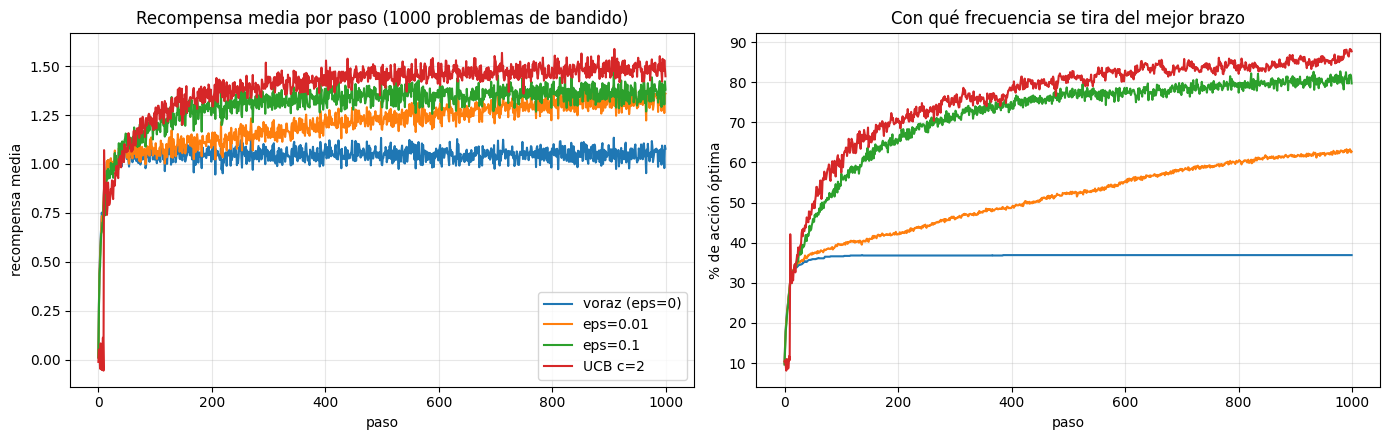

método           recompensa media, pasos 1-1000 recompensa media, últimos 100 % óptimo, últimos 100
voraz (eps=0)                         1.041                    1.050                  36.9
eps=0.01                              1.207                    1.325                  62.2
eps=0.1                               1.305                    1.362                  80.4
UCB c=2                               1.389                    1.485                  85.7
(2.8 s)


In [2]:
K, STEPS, RUNS = 10, 1000, 1000

def run_bandit(method, param, seed=0):
    rng = np.random.default_rng(seed)
    q_true = rng.normal(0, 1, (RUNS, K))
    best = q_true.argmax(1)
    Q = np.zeros((RUNS, K)); N = np.zeros((RUNS, K))
    rows = np.arange(RUNS)
    reward_curve, optimal_curve = np.zeros(STEPS), np.zeros(STEPS)
    for t in range(1, STEPS + 1):
        if method == "ucb":
            with np.errstate(divide="ignore", invalid="ignore"):
                bonus = np.where(N == 0, np.inf, param * np.sqrt(np.log(t) / N))
            score = Q + bonus
        else:
            score = Q + rng.uniform(0, 1e-9, Q.shape)             # desempate aleatorio
        a = score.argmax(1)
        if method == "eps":
            explore = rng.random(RUNS) < param
            a = np.where(explore, rng.integers(0, K, RUNS), a)
        r = rng.normal(q_true[rows, a], 1.0)
        N[rows, a] += 1
        Q[rows, a] += (r - Q[rows, a]) / N[rows, a]              # promedio muestral incremental
        reward_curve[t - 1] = r.mean()
        optimal_curve[t - 1] = (a == best).mean()
    return reward_curve, optimal_curve

configs = [("voraz (eps=0)", "eps", 0.0), ("eps=0.01", "eps", 0.01), ("eps=0.1", "eps", 0.1), ("UCB c=2", "ucb", 2.0)]
t0 = time.time()
bandit_res = {name: run_bandit(m, p) for name, m, p in configs}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, (rc, oc) in bandit_res.items():
    axes[0].plot(rc, label=name); axes[1].plot(100 * oc, label=name)
axes[0].set_title("Recompensa media por paso (1000 problemas de bandido)"); axes[0].set_xlabel("paso"); axes[0].set_ylabel("recompensa media")
axes[1].set_title("Con qué frecuencia se tira del mejor brazo"); axes[1].set_xlabel("paso"); axes[1].set_ylabel("% de acción óptima")
axes[0].legend(); plt.tight_layout(); plt.show()

print(f"{'método':16s} {'recompensa media, pasos 1-1000':>26s} {'recompensa media, últimos 100':>24s} {'% óptimo, últimos 100':>21s}")
for name, (rc, oc) in bandit_res.items():
    print(f"{name:16s} {rc.mean():26.3f} {rc[-100:].mean():24.3f} {100*oc[-100:].mean():21.1f}")
print(f"({time.time()-t0:.1f} s)")

**Lectura.** El agente voraz se aferra al primer brazo que pareció decente y rara vez encuentra el mejor: es rápido al principio y se queda plano después. Explorar un poco ($\varepsilon = 0.1$) sube más despacio al inicio pero termina claramente más alto, porque sigue muestreando y acaba identificando el mejor brazo. Un $\varepsilon$ menor explora menos y tarda más en encontrarlo, así que en 1000 pasos queda entre el voraz y 0.1 (con más pasos lo favorecería). UCB es el mejor de los cuatro en los pasos finales, porque su exploración es *dirigida*: deja de tirar de los brazos de los que ya está seguro que son malos. Los números exactos dependen de la distribución del problema (UCB es sensible a $c$, y con otras distribuciones de recompensa épsilon-voraz puede ganar), así que léelo como una ilustración del equilibrio, no como un ranking de algoritmos. Ni siquiera el mejor método llega al 100 % de tiradas óptimas: las recompensas son ruidosas y las medias de los mejores brazos están cerca.

## 3. Q-learning en un mundo de cuadrícula con precipicio

Ahora añadimos **estados** y **consecuencias retrasadas**. La tarea clásica del paseo por el precipicio (Sutton y Barto, 2018, ejemplo 6.6) es una cuadrícula de 4 × 12. El agente empieza abajo a la izquierda, la meta está abajo a la derecha, y la fila inferior entre ambos es un **precipicio**. Cada paso cuesta $-1$ (así que los caminos cortos son mejores). Caer al precipicio cuesta $-100$ y devuelve al agente al inicio. El camino corto va justo por el borde del precipicio. El largo va por arriba y es seguro.

**Q-learning** (Watkins y Dayan, 1992) mantiene una tabla $Q(s,a)$ y, tras cada paso $(s, a, r, s')$, la acerca a una estimación mejor:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \Big[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \Big]$$

Aquí $\alpha$ es la tasa de aprendizaje y el término entre corchetes es el **error de diferencia temporal** (TD, temporal difference): la diferencia entre lo que ocurrió (la recompensa más nuestra estimación de la mejor continuación) y lo que habíamos predicho. Mientras aprende, el agente sigue una política **épsilon-voraz** ($\varepsilon = 0.1$), la misma regla de exploración de la sección 2. **SARSA** es idéntico salvo que usa la acción $a'$ que *realmente toma después* en lugar del máximo, así que aprende el valor de la propia política exploradora. Q-learning es **fuera de política** (aprende sobre la política voraz mientras se comporta de otra manera), SARSA es **en política**.

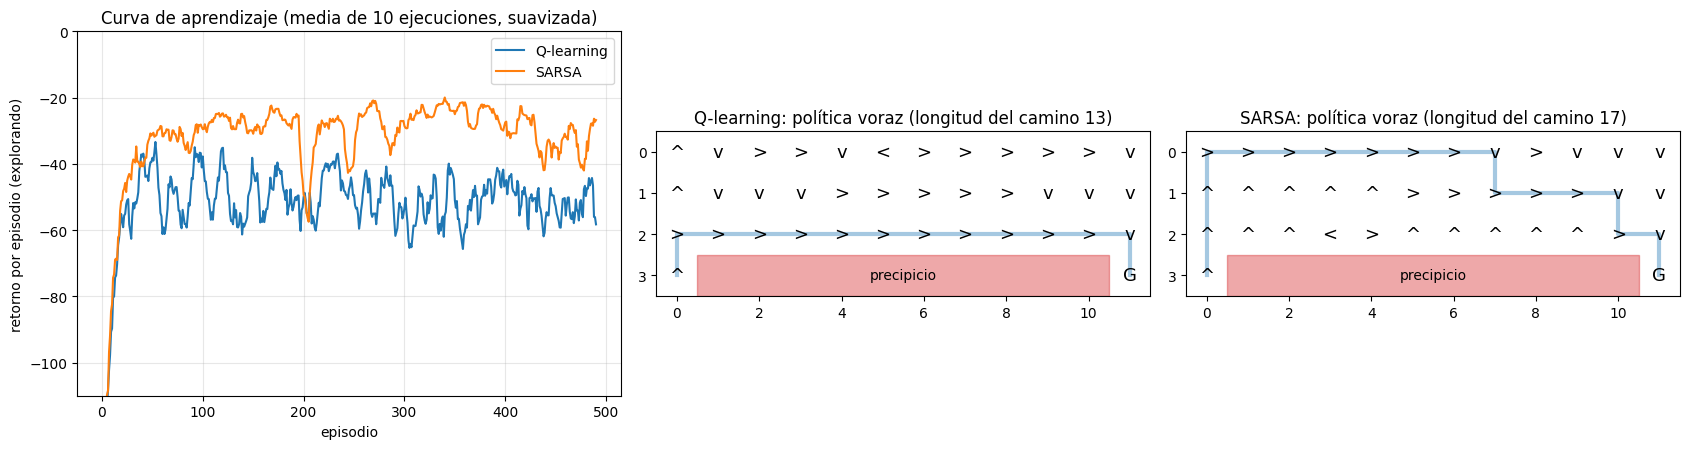

retorno medio por episodio durante el entrenamiento, últimos 100 episodios: Q-learning -51.9, SARSA -31.5
longitud del camino voraz, semilla 0: Q-learning 13 pasos, SARSA 17 pasos (el más corto posible: 13)
(8.5 s)


In [3]:
ROWS, COLS = 4, 12
START, GOAL = (3, 0), (3, 11)
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]          # arriba, derecha, abajo, izquierda
ARROWS = ["^", ">", "v", "<"]

def grid_step(s, a):
    r, c = s[0] + MOVES[a][0], s[1] + MOVES[a][1]
    r, c = min(max(r, 0), ROWS - 1), min(max(c, 0), COLS - 1)
    if r == 3 and 1 <= c <= 10:                      # el precipicio
        return START, -100.0, False
    return (r, c), -1.0, (r, c) == GOAL

def train_grid(algo, seed, episodes=500, alpha=0.5, gamma=1.0, eps=0.1):
    rng = np.random.default_rng(seed)
    Q = np.zeros((ROWS, COLS, 4))
    pick = lambda s: int(rng.integers(4)) if rng.random() < eps else int(np.argmax(Q[s] + rng.uniform(0, 1e-9, 4)))
    returns = []
    for ep in range(episodes):
        s, a, total, done, steps = START, None, 0.0, False, 0
        a = pick(s)
        while not done and steps < 500:
            s2, r, done = grid_step(s, a)
            a2 = pick(s2)
            target = r + (0.0 if done else gamma * (Q[s2].max() if algo == "q" else Q[s2][a2]))
            Q[s][a] += alpha * (target - Q[s][a])
            s, a, total, steps = s2, a2, total + r, steps + 1
        returns.append(total)
    return Q, np.array(returns)

t0 = time.time()
res = {algo: [train_grid(algo, seed) for seed in range(10)] for algo in ["q", "sarsa"]}
curves = {algo: np.mean([r for _, r in res[algo]], axis=0) for algo in res}
smooth = lambda x, k=10: np.convolve(x, np.ones(k) / k, mode="valid")

def greedy_path(Q):
    s, path = START, [START]
    for _ in range(60):
        s, _, done = grid_step(s, int(np.argmax(Q[s])))
        path.append(s)
        if done: break
    return path

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.1, 1, 1]})
axes[0].plot(smooth(curves["q"]), label="Q-learning"); axes[0].plot(smooth(curves["sarsa"]), label="SARSA")
axes[0].set_ylim(-110, 0); axes[0].set_xlabel("episodio"); axes[0].set_ylabel("retorno por episodio (explorando)")
axes[0].set_title("Curva de aprendizaje (media de 10 ejecuciones, suavizada)"); axes[0].legend()
for ax, (algo, title) in zip(axes[1:], [("q", "Q-learning: política voraz"), ("sarsa", "SARSA: política voraz")]):
    Q = res[algo][0][0]                                   # ejecución con semilla 0
    ax.set_xlim(-0.5, COLS - 0.5); ax.set_ylim(ROWS - 0.5, -0.5); ax.set_aspect("equal"); ax.grid(False)
    ax.add_patch(plt.Rectangle((0.5, 2.5), 10, 1, color="tab:red", alpha=0.4)); ax.text(5.5, 3, "precipicio", ha="center", va="center")
    path = greedy_path(Q)
    ax.plot([p[1] for p in path], [p[0] for p in path], color="tab:blue", lw=3, alpha=0.4)
    for r in range(ROWS):
        for c in range(COLS):
            if r == 3 and 1 <= c <= 10: continue
            ax.text(c, r, "G" if (r, c) == GOAL else ARROWS[int(np.argmax(Q[r, c]))], ha="center", va="center", fontsize=13)
    ax.set_title(title + f" (longitud del camino {len(path)-1})")
plt.tight_layout(); plt.show()

last = {a: curves[a][-100:].mean() for a in curves}
print(f"retorno medio por episodio durante el entrenamiento, últimos 100 episodios: Q-learning {last['q']:.1f}, SARSA {last['sarsa']:.1f}")
print(f"longitud del camino voraz, semilla 0: Q-learning {len(greedy_path(res['q'][0][0]))-1} pasos, SARSA {len(greedy_path(res['sarsa'][0][0]))-1} pasos (el más corto posible: 13)")
print(f"({time.time()-t0:.1f} s)")

**Lectura.** Ambos agentes aprenden: el retorno empieza cerca de $-100$ o peor (cae al precipicio mientras explora) y sube de forma constante. Las dos políticas difieren de una manera que es el centro del ejemplo. Q-learning aprende los valores de la política *voraz óptima*, que bordea el precipicio (el camino más corto). Pero mientras aprende sigue dando pasos al azar el 10 % de las veces, y junto a un precipicio un paso al azar sale caro, así que su retorno *durante el entrenamiento* es menor que el de SARSA. SARSA aprende el valor de la política que realmente ejecuta, pasos aleatorios incluidos, y por eso prefiere la ruta más larga y segura. Ninguno está "equivocado": optimizan cosas distintas. Si el agente se va a comportar de forma voraz tras entrenar, el camino de Q-learning es mejor. Si la exploración debe seguir activa (o los errores son caros), la cautela de SARSA compensa. (En tu propia ejecución el camino exacto puede diferir en unas pocas casillas, pues 500 episodios de una tabla ruidosa no están del todo convergidos.)

**Dónde deja de funcionar.** Una tabla necesita una entrada por (estado, acción). Una cuadrícula de 4 × 12 tiene 48 estados. Una partida de Go tiene unos $10^{170}$. La solución es sustituir la tabla por una red neuronal $Q_\theta(s,a)$, que es lo que hacen las redes Q profundas (Mnih et al., 2015), o aprender la política directamente, que es lo que hacemos a continuación.

## 4. Gradiente de política: REINFORCE en cart-pole

En lugar de aprender valores y actuar de forma voraz, los métodos de **gradiente de política** parametrizan la propia política, $\pi_\theta(a \mid s)$, como una red neuronal con pesos $\theta$, y hacen ascenso por gradiente sobre el retorno esperado $J(\theta)$. El **teorema del gradiente de política** da el gradiente como una esperanza que podemos estimar a partir de episodios muestreados:

$$\nabla_\theta J(\theta) = \mathbb{E}\Big[ \sum_t \nabla_\theta \log \pi_\theta(a_t \mid s_t)\; G_t \Big]$$

En palabras: sube la log-probabilidad de cada acción tomada, en proporción al retorno que vino después. Los buenos resultados hacen más probables sus acciones, los malos las hacen menos probables. El estimador que hace exactamente esto con episodios muestreados es **REINFORCE** (Williams, 1992). En el código minimizamos la "pérdida" $-\sum_t \log\pi_\theta(a_t|s_t)\, G_t$, y la autodiferenciación produce el gradiente.

**La tarea.** Implementamos nosotros el clásico **cart-pole** (Barto, Sutton y Anderson, 1983): un palo articulado sobre un carro que desliza por una vía. El agente empuja el carro a izquierda o derecha con una fuerza fija cada 0.02 s. El estado es $(x, \dot x, \theta, \dot\theta)$ (posición del carro, velocidad del carro, ángulo del palo, velocidad angular del palo). La recompensa es $+1$ por cada paso en que el palo se mantiene a menos de 12 grados de la vertical y el carro a menos de 2.4 unidades del centro. Un episodio se corta a los 200 pasos, así que **200 es la mejor puntuación posible**. El entorno de abajo está vectorizado sobre muchas copias simultáneas para poder ejecutar 16 episodios a la vez.

In [4]:
class CartPole:
    # física clásica de cart-pole, integración de Euler, vectorizada sobre n copias independientes
    g, mc, mp, l, force, tau = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    def __init__(self, n, rng): self.n, self.rng = n, rng
    def reset(self):
        self.x = self.rng.uniform(-0.05, 0.05, (self.n, 4))
        return self.x.copy()
    def step(self, a):
        x, xd, th, thd = self.x.T
        f = np.where(a == 1, self.force, -self.force)
        c, s = np.cos(th), np.sin(th); tm = self.mc + self.mp; pl = self.mp * self.l
        tmp = (f + pl * thd ** 2 * s) / tm
        tha = (self.g * s - c * tmp) / (self.l * (4 / 3 - self.mp * c ** 2 / tm))
        xa = tmp - pl * tha * c / tm
        self.x = np.stack([x + self.tau * xd, xd + self.tau * xa, th + self.tau * thd, thd + self.tau * tha], 1)
        done = (np.abs(self.x[:, 0]) > 2.4) | (np.abs(self.x[:, 2]) > 0.2095)
        return self.x.copy(), done

HORIZON, GAMMA = 200, 0.99
def mlp(out): return nn.Sequential(nn.Linear(4, 32), nn.Tanh(), nn.Linear(32, out))

def rollout(policy, n, rng):
    # ejecuta n episodios en paralelo; M[t, i] = 1 mientras el episodio i sigue en marcha en el paso t (ese paso gana recompensa +1)
    env = CartPole(n, rng); s = env.reset(); alive = np.ones(n, bool)
    S = np.zeros((HORIZON, n, 4), np.float32); A = np.zeros((HORIZON, n), np.int64); M = np.zeros((HORIZON, n), np.float32)
    for t in range(HORIZON):
        S[t], M[t] = s, alive
        with torch.no_grad():
            a = torch.distributions.Categorical(logits=policy(torch.tensor(s, dtype=torch.float32))).sample().numpy()
        A[t] = a
        s, done = env.step(a)
        alive = alive & ~done
        if not alive.any(): break
    return S, A, M

def returns_to_go(M, gamma=GAMMA):
    G = np.zeros_like(M); run = np.zeros(M.shape[1], np.float32)
    for t in reversed(range(len(M))):
        run = M[t] + gamma * run
        G[t] = run * M[t]
    return G

# una política que siempre empuja a la derecha falla rápido; una red sin entrenar es poco mejor
rng0 = np.random.default_rng(0); torch.manual_seed(0)
S_, A_, M_ = rollout(mlp(2), 64, rng0)
print(f"política sin entrenar (casi aleatoria): longitud media de episodio {M_.sum(0).mean():.1f} pasos (máximo posible 200)")

política sin entrenar (casi aleatoria): longitud media de episodio 20.3 pasos (máximo posible 200)


### Por qué REINFORCE es ruidoso, y qué hace una línea base

El estimador del gradiente es **insesgado** (correcto en promedio) pero su **varianza** de una muestra a otra puede ser grande: un episodio con suerte y un retorno alto empuja hacia arriba *todas* sus acciones, incluidas las malas. Un remedio estándar es restar una **línea base** (baseline) $b$ que no dependa de la acción:

$$\nabla_\theta J(\theta) = \mathbb{E}\Big[ \sum_t \nabla_\theta \log \pi_\theta(a_t \mid s_t)\,\big(G_t - b(s_t)\big) \Big]$$

Restar $b$ no cambia el gradiente esperado (porque $\mathbb{E}_{a \sim \pi}[\nabla_\theta \log \pi_\theta(a|s)] = 0$) pero puede reducir mucho la varianza. La diferencia $G_t - b(s_t)$ se llama **ventaja**: cuánto mejor que lo habitual fue el resultado. Aquí la línea base para la medición de abajo es simplemente el retorno futuro medio en el mismo paso $t$, estimado con un lote aparte de 64 episodios.

Lo medimos directamente. Para una política dada calculamos el gradiente 60 veces, cada vez con un lote nuevo de 16 episodios, con y sin la línea base. Informamos la **varianza total** (la suma, sobre todos los pesos, de la varianza del gradiente de ese peso) y una **relación señal/ruido**: la longitud del gradiente medio dividida por la raíz cuadrada de la varianza total.

In [5]:
def flat_grad(policy):
    return torch.cat([p.grad.flatten() for p in policy.parameters()]).numpy().copy()

def grad_estimates(policy, baseline, n_est=60, n_ep=16, seed=0):
    rng = np.random.default_rng(seed)
    b = None
    if baseline:                                          # retorno futuro medio por paso de tiempo, de un lote APARTE
        S, A, M = rollout(policy, 64, rng); G = returns_to_go(M)
        b = (G * M).sum(1) / np.maximum(M.sum(1), 1)
    grads = []
    for _ in range(n_est):
        S, A, M = rollout(policy, n_ep, rng); G = returns_to_go(M)
        adv = torch.tensor(G - (b[:len(G), None] if b is not None else 0.0))
        lp = torch.distributions.Categorical(logits=policy(torch.tensor(S))).log_prob(torch.tensor(A))
        loss = -(lp * adv * torch.tensor(M)).sum() / n_ep
        policy.zero_grad(); loss.backward(); grads.append(flat_grad(policy))
    return np.array(grads)

def variance_report(policy, name):
    out = {}
    for label, use_b in [("sin línea base", False), ("con línea base", True)]:
        g = grad_estimates(policy, use_b)
        total_var = g.var(0).sum()
        out[label] = (total_var, np.linalg.norm(g.mean(0)) / np.sqrt(total_var))
    print(f"{name}")
    for label, (v, snr) in out.items():
        print(f"  {label:14s} varianza total {v:12.1f}   señal/ruido {snr:5.2f}")
    print(f"  varianza reducida {out['sin línea base'][0] / out['con línea base'][0]:.1f}x")
    return out

t0 = time.time()
torch.manual_seed(0); pol_init = mlp(2)
var_init = variance_report(pol_init, "política inicial (sin entrenar)")
print(f"({time.time()-t0:.1f} s)")

política inicial (sin entrenar)
  sin línea base varianza total        366.9   señal/ruido  1.13
  con línea base varianza total        218.8   señal/ruido  1.88
  varianza reducida 1.7x
(5.9 s)


### Entrenar REINFORCE con y sin línea base aprendida

Promediar los retornos en cada paso de tiempo es una buena línea base para medir, pero una mejor depende del **estado**: $b(s) = V(s)$, una segunda red entrenada para predecir el retorno. Ahora entrenamos cuatro variantes y las comparamos (las dos últimas llegan en la sección 5). Para que la comparación sea justa, cada método recoge 16 episodios por iteración y usa Adam con tasa de aprendizaje 0.01, una red de política 4-32-2 y tres semillas. La función de entrenamiento se escribe una sola vez, en un único lugar, de modo que los métodos solo difieren en cómo convierten los retornos en una pérdida.

* `reinforce`: pérdida $-\log\pi(a|s)\,G_t$ (sin línea base);
* `baseline`: pérdida $-\log\pi(a|s)\,(G_t - V(s))$, con $V$ aprendida por regresión sobre $G_t$.

## 5. Actor-crítico y PPO

### El paso actor-crítico y el objetivo PPO, definidos

Dos ingredientes más, implementados en la misma función.

**Actor-crítico.** REINFORCE espera al final del episodio para conocer $G_t$, y $G_t$ suma muchas recompensas aleatorias, de ahí la varianza. Un **actor-crítico** sustituye $G_t$ por una estimación de un paso construida con la función de valor aprendida (el "crítico"): la **ventaja TD**

$$A_t = r_{t+1} + \gamma V(s_{t+1}) - V(s_t).$$

Tiene mucha menos varianza (contiene una recompensa aleatoria en lugar de cientos) pero está **sesgada**, porque $V$ es solo una estimación. La política ("actor") se actualiza con $-\log\pi(a_t|s_t)\,A_t$ y el crítico se entrena para reducir $A_t^2$.

**PPO.** Los métodos de gradiente de política dan un paso de gradiente por lote y lo descartan, lo cual es un desperdicio. Reutilizar un lote durante varios pasos es peligroso: la política se aleja de la que recogió los datos y el estimador deja de ser válido. **PPO** (Schulman et al., 2017) lo arregla con un objetivo *recortado*. Sea $\rho_t(\theta) = \pi_\theta(a_t|s_t) / \pi_{\theta_{old}}(a_t|s_t)$ la razón de probabilidades entre la política nueva y la antigua, y $\hat A_t$ la ventaja. Entonces

$$L^{\text{CLIP}}(\theta) = \mathbb{E}\Big[ \min\big( \rho_t \hat A_t,\ \operatorname{clip}(\rho_t, 1-\epsilon, 1+\epsilon)\, \hat A_t \big) \Big]$$

con $\epsilon = 0.2$. Si la ventaja es positiva queremos un $\rho$ mayor, pero una vez que supera $1+\epsilon$ el objetivo es plano y el gradiente desaparece: no hay incentivo para moverse más. Si la ventaja es negativa ocurre lo mismo por debajo de $1-\epsilon$. El recorte mantiene la política nueva cerca de la antigua, así que podemos hacer varias épocas sobre el mismo lote sin riesgo. El gráfico muestra la forma del objetivo.

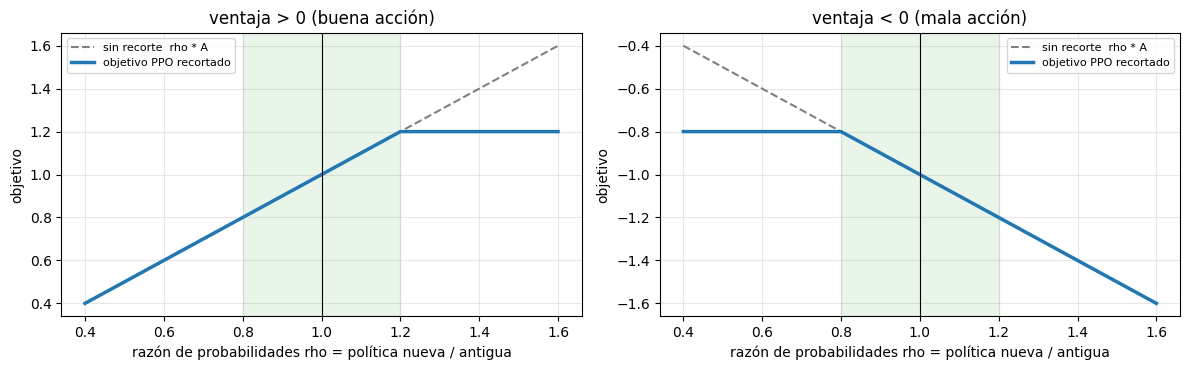

In [6]:
rho = np.linspace(0.4, 1.6, 400); eps_clip = 0.2
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, adv, title in zip(axes, [1.0, -1.0], ["ventaja > 0 (buena acción)", "ventaja < 0 (mala acción)"]):
    unclipped = rho * adv
    clipped = np.minimum(rho * adv, np.clip(rho, 1 - eps_clip, 1 + eps_clip) * adv)
    ax.plot(rho, unclipped, "--", color="gray", label="sin recorte  rho * A")
    ax.plot(rho, clipped, color="tab:blue", lw=2.5, label="objetivo PPO recortado")
    ax.axvline(1, color="k", lw=0.8); ax.axvspan(1 - eps_clip, 1 + eps_clip, color="tab:green", alpha=0.1)
    ax.set_xlabel("razón de probabilidades rho = política nueva / antigua"); ax.set_ylabel("objetivo"); ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.** Con una buena acción, el objetivo crece con $\rho$ solo hasta $1.2$ y es plano más allá. Con una mala acción, cae al reducirse $\rho$ solo hasta $0.8$. Dentro de la banda sombreada el gradiente es el gradiente de política habitual. Fuera de ella, en la dirección "rentable", el gradiente es exactamente cero. Ese es todo el truco, sin maquinaria de segundo orden.

Ahora el experimento. `ppo` usa la ventaja $G_t - V(s_t)$ normalizada a media 0 y desviación típica 1 dentro del lote, 4 épocas por lote y el recorte de arriba. Como ablación, `ppo_noclip` es idéntico pero sin el recorte (y sin el mínimo), así que simplemente da 4 pasos de gradiente de política normales sobre un lote desactualizado.

In [7]:
def train(method, seed, iters=40, n_ep=16, lr=1e-2):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    pi, v = mlp(2), mlp(1)
    opt = torch.optim.Adam(list(pi.parameters()) + list(v.parameters()), lr=lr)
    curve = []
    for it in range(iters):
        S, A, M = rollout(pi, n_ep, rng)
        St, At, Mt, G = torch.tensor(S), torch.tensor(A), torch.tensor(M), torch.tensor(returns_to_go(M))
        curve.append(M.sum(0).mean())
        with torch.no_grad():
            lp_old = torch.distributions.Categorical(logits=pi(St)).log_prob(At)
        epochs = 4 if method.startswith("ppo") else 1
        for _ in range(epochs):
            lp = torch.distributions.Categorical(logits=pi(St)).log_prob(At)
            V = v(St).squeeze(-1) * 100                       # valor escalado para que la salida quede cerca de 1
            if method == "reinforce":
                adv, target = G, None
            elif method == "baseline":
                adv, target = G - V.detach(), G
            elif method == "actor_critic":
                nxt_alive = torch.tensor(np.concatenate([M[1:], np.zeros((1, n_ep), np.float32)]))
                Vn = torch.cat([V[1:], torch.zeros(1, n_ep)]).detach() * nxt_alive
                target = (1 + GAMMA * Vn)                     # r + gamma V(s'), la recompensa es +1 mientras vive
                adv = target - V.detach()
            else:                                             # ppo, ppo_noclip
                adv, target = G - V.detach(), G
                adv = (adv - adv[Mt > 0].mean()) / (adv[Mt > 0].std() + 1e-8)
            if method == "ppo":
                ratio = torch.exp(lp - lp_old)
                obj = torch.min(ratio * adv, torch.clamp(ratio, 1 - 0.2, 1 + 0.2) * adv)
            elif method == "ppo_noclip":
                obj = torch.exp(lp - lp_old) * adv
            else:
                obj = lp * adv
            loss = -(obj * Mt).sum() / Mt.sum()
            if target is not None:
                loss = loss + (((target - V) ** 2) * Mt).sum() / Mt.sum() / 1e4
            opt.zero_grad(); loss.backward(); opt.step()
    return np.array(curve), pi

methods = ["reinforce", "baseline", "actor_critic", "ppo", "ppo_noclip"]
t0 = time.time(); results = {}; trained = {}
for m in methods:
    runs = [train(m, seed) for seed in range(3)]
    results[m] = np.array([c for c, _ in runs]); trained[m] = runs[0][1]
    print(f"{m:13s} listo en {time.time()-t0:5.1f} s (acumulado)")

reinforce     listo en  19.7 s (acumulado)


baseline      listo en  37.8 s (acumulado)


actor_critic  listo en  47.2 s (acumulado)


ppo           listo en  75.8 s (acumulado)


ppo_noclip    listo en 119.5 s (acumulado)


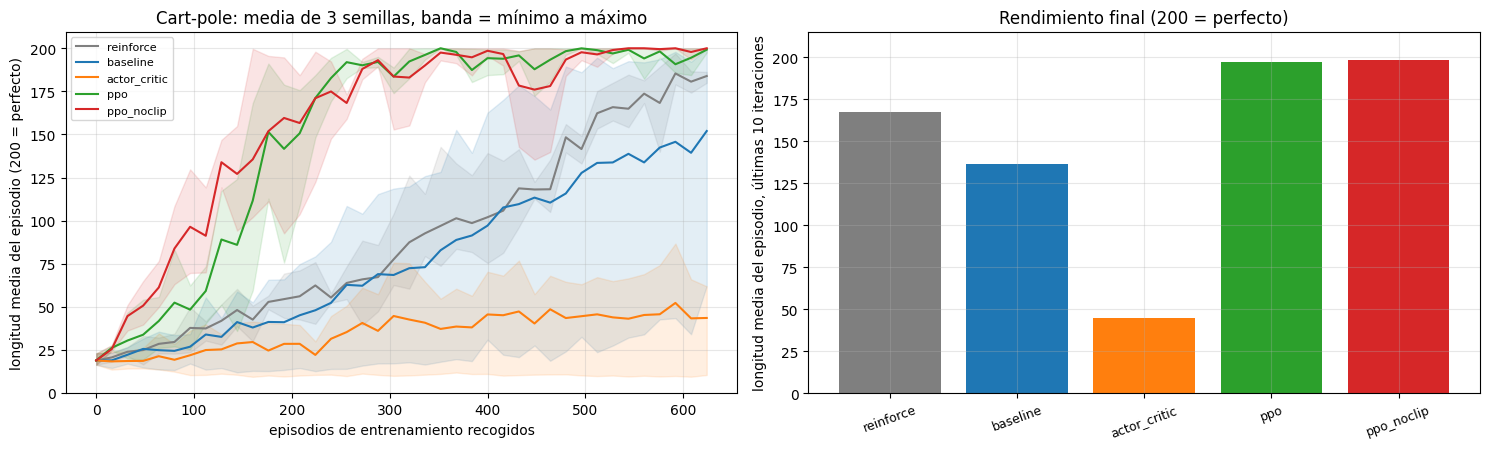

método        episodios hasta longitud media 150 final (últimas 10 iter.) peor semilla, final
reinforce                                    512                  167.5              162.9
baseline                                     624                  136.3               35.6
actor_critic                               nunca                   45.1               10.0
ppo                                          176                  197.0              194.9
ppo_noclip                                   176                  198.4              196.7
(total hasta ahora 139 s)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
colors = {"reinforce": "tab:gray", "baseline": "tab:blue", "actor_critic": "tab:orange", "ppo": "tab:green", "ppo_noclip": "tab:red"}
for m in methods:
    mean, lo, hi = results[m].mean(0), results[m].min(0), results[m].max(0)
    x = np.arange(len(mean)) * 16
    axes[0].plot(x, mean, color=colors[m], label=m); axes[0].fill_between(x, lo, hi, color=colors[m], alpha=0.12)
axes[0].set_xlabel("episodios de entrenamiento recogidos"); axes[0].set_ylabel("longitud media del episodio (200 = perfecto)")
axes[0].set_title("Cart-pole: media de 3 semillas, banda = mínimo a máximo"); axes[0].legend(fontsize=8)

first = {m: next((i * 16 for i, v_ in enumerate(results[m].mean(0)) if v_ >= 150), None) for m in methods}
last = {m: results[m].mean(0)[-10:].mean() for m in methods}
axes[1].bar(range(len(methods)), [last[m] for m in methods], color=[colors[m] for m in methods])
axes[1].set_xticks(range(len(methods))); axes[1].set_xticklabels(methods, rotation=20, fontsize=9)
axes[1].set_ylabel("longitud media del episodio, últimas 10 iteraciones"); axes[1].set_ylim(0, 215)
axes[1].set_title("Rendimiento final (200 = perfecto)")
plt.tight_layout(); plt.show()

print(f"{'método':13s} {'episodios hasta longitud media 150':>34s} {'final (últimas 10 iter.)':>22s} {'peor semilla, final':>18s}")
for m in methods:
    worst = results[m][:, -10:].mean(1).min()
    print(f"{m:13s} {str(first[m]) if first[m] is not None else 'nunca':>34s} {last[m]:22.1f} {worst:18.1f}")
print(f"(total hasta ahora {time.time()-T_START:.0f} s)")

In [9]:
t0 = time.time()
torch.manual_seed(1)
pol_mid = trained["baseline"]
var_mid = variance_report(pol_mid, "una política parcialmente entrenada con REINFORCE y línea base (semilla 0, 40 iteraciones)")
print(f"({time.time()-t0:.1f} s)")

una política parcialmente entrenada con REINFORCE y línea base (semilla 0, 40 iteraciones)
  sin línea base varianza total     112483.8   señal/ruido  0.16
  con línea base varianza total       1103.2   señal/ruido  0.52
  varianza reducida 102.0x
(48.7 s)


**Lectura.** Cuatro observaciones honestas, y una puede sorprenderte.

1. **Varianza.** La línea base reduce la varianza de la estimación del gradiente, y la relación señal/ruido sube en consecuencia (números impresos arriba). Para la política sin entrenar la reducción es de unas 2 veces. Para la política parcialmente entrenada, con episodios largos y retornos grandes, es muy grande (unas cien veces en la ejecución mostrada, y varía entre ejecuciones): el retorno bruto es un número grande casi todo compartido por todas las acciones, y la línea base elimina esa parte compartida. Es justo lo que promete la teoría, y es una *medición*, no una suposición. (Ambos estimadores son ruidosos con 60 repeticiones; lee los órdenes de magnitud, no los dígitos.)
2. **Pero aprender más rápido no está garantizado.** En esta tarea diminuta REINFORCE simple con Adam ya aprende bien, y la línea base aprendida *no* aceleró el entrenamiento: tardó algo más en llegar a una longitud media de 150 y una de sus tres semillas quedó muy rezagada al final (ver la columna "worst seed"). Al principio la red de valor es mala prediciendo, así que mete su propio error en la ventaja. Con solo tres semillas esta diferencia está dentro de la dispersión entre semillas, así que no la leas como un efecto demostrado en ningún sentido. Una menor varianza del gradiente debería ayudar más cuando la tarea es más difícil, los lotes más pequeños o la tasa de aprendizaje mayor (ejercicio 5).
3. **PPO fue el más fuerte aquí.** `ppo` llegó a una longitud media de 150 en aproximadamente un tercio de los episodios de los demás y terminó cerca del máximo con todas las semillas buenas. Hace cuatro actualizaciones por lote, así que también hace más cómputo por episodio: es una ventaja de eficiencia de muestras. **El recorte en sí importó poco en esta tarea fácil**: la ablación sin recorte igualó su velocidad y su puntuación final (ambas cerca de 200), así que aquí el recorte no marcó una diferencia medible. Gran parte de la ganancia de PPO aquí viene de reutilizar el lote y de normalizar la ventaja. El recorte es un seguro que compensa cuando se fuerzan la tasa de aprendizaje o el número de épocas (ejercicio 6), no algo que este juguete demuestre.
4. **El actor-crítico de un paso fue el más lento** y nunca llegó a 150. Su crítico se apoya en sus propias estimaciones, que empiezan mal, así que las ventajas están sesgadas al principio, y una actualización por lote es poco. Con un crítico más rápido, varios pasos de crítico por lote o la estimación generalizada de ventaja (Schulman et al., 2016, que mezcla los dos estimadores) lo haría mucho mejor. Tómalo como "el actor-crítico más simple, sin ajustar", no como un veredicto sobre los métodos actor-crítico.

**Dónde difiere el juguete de los sistemas reales.** Cart-pole tiene 4 entradas, 2 acciones y episodios de 200 pasos, y se resuelve con 16 episodios por iteración en una CPU en segundos. Los usos industriales (robótica, juegos, control de centros de datos) tienen imágenes o flujos de sensores como estados, acciones continuas, episodios de miles de pasos, y necesitan muchos millones de pasos de entorno y a menudo un simulador que corre en muchas máquinas. Además nuestras curvas son un promedio de solo tres semillas: los resultados de RL son notoriamente sensibles a la semilla, y los artículos serios informan muchas más.

## 6. Explotación de la recompensa (reward hacking)

Un agente de RL maximiza **la recompensa que escribiste**, no **el resultado que querías**. Cuando ambos difieren, el agente encuentra la brecha. Esto es la **explotación de la recompensa** (reward hacking, también llamada especificación tramposa o specification gaming, un caso de la ley de Goodhart: cuando una medida se convierte en objetivo deja de ser una buena medida). Es uno de los problemas centrales de la seguridad de la IA (Amodei et al., 2016; Skalse et al., 2022), y un ejemplo real conocido es un agente de un juego de carreras de lanchas que aprendió a dar vueltas sin parar recogiendo objetivos de bonificación en lugar de terminar la carrera (Clark y Amodei, 2016).

Reproducimos la idea en el entorno más pequeño posible. Una **pista** de 8 casillas, posiciones 0 a 7. El agente empieza en 0 y la tarea prevista es llegar a la **meta** en la casilla 7 (recompensa $+10$, el episodio termina). Quien diseña, queriendo "fomentar el avance", añade además un **punto de control** en la casilla 2 que paga $+1$ cada vez que el agente *entra* en él. Un episodio se corta tras 60 pasos. El agente usa el Q-learning de la sección 3, con $\gamma = 0.99$.

Comparamos dos diseños de recompensa:

* **recompensa proxy** (mal especificada): $+1$ cada vez que el agente entra en la casilla 2;
* **recompensa corregida**: $+1$ solo la *primera* vez (el estado del agente ahora incluye una marca "punto de control ya cobrado", así que puede distinguirlo).

Informamos dos números del agente voraz ya entrenado: la puntuación **proxy** que estaba optimizando (recompensa de punto de control cobrada) y el objetivo **verdadero** que nos importa (¿llegó a la meta?).

diseño de recompensa                           llegó a la meta recompensa de control cobrada
recompensa proxy (el punto de control paga siempre)                0%                          30.0
recompensa corregida (el punto de control paga una vez)              100%                          11.0

camino voraz del primer agente entrenado con la recompensa proxy      : [0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1] ...
camino voraz del primer agente entrenado con la recompensa corregida  : [0, 1, 2, 3, 4, 5, 6, 7]


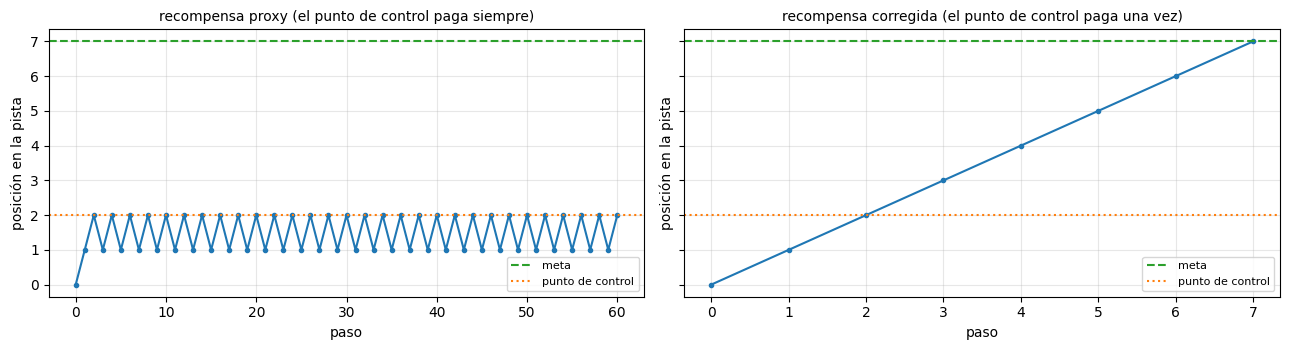

(21.2 s)


In [10]:
TRACK, CHECK, GOAL_POS, HORIZON_H = 8, 2, 7, 60

def track_step(pos, got, a, once):
    pos2 = min(max(pos + (1 if a == 1 else -1), 0), TRACK - 1)
    r, done = 0.0, False
    if pos2 == CHECK and pos != CHECK:
        if not (once and got): r += 1.0
        got = 1
    if pos2 == GOAL_POS: r, done = r + 10.0, True
    return pos2, got, r, done

def train_track(once, seed=0, episodes=1500, alpha=0.1, gamma=0.99, eps=0.2):
    rng = np.random.default_rng(seed); Q = np.zeros((TRACK, 2, 2))
    for ep in range(episodes):
        pos, got = 0, 0
        for t in range(HORIZON_H):
            a = int(rng.integers(2)) if rng.random() < eps else int(np.argmax(Q[pos, got] + rng.uniform(0, 1e-9, 2)))
            pos2, got2, r, done = track_step(pos, got, a, once)
            Q[pos, got, a] += alpha * (r + (0 if done else gamma * Q[pos2, got2].max()) - Q[pos, got, a])
            pos, got = pos2, got2
            if done: break
    return Q

def evaluate_track(Q, once):
    pos, got, proxy, path = 0, 0, 0.0, [0]
    for t in range(HORIZON_H):
        pos, got, r, done = track_step(pos, got, int(np.argmax(Q[pos, got])), once)
        proxy += r; path.append(pos)
        if done: break
    return proxy, pos == GOAL_POS, path

t0 = time.time()
rows = []
for once, name in [(False, "recompensa proxy (el punto de control paga siempre)"), (True, "recompensa corregida (el punto de control paga una vez)")]:
    reached, proxies, paths = [], [], []
    for seed in range(5):
        proxy, ok, path = evaluate_track(train_track(once, seed), once)
        reached.append(ok); proxies.append(proxy); paths.append(path)
    rows.append((name, np.mean(reached), np.mean(proxies), paths[0]))

print(f"{'diseño de recompensa':44s} {'llegó a la meta':>17s} {'recompensa de control cobrada':>29s}")
for name, ok, px, _ in rows:
    print(f"{name:44s} {100*ok:16.0f}% {px:29.1f}")
print("\ncamino voraz del primer agente entrenado con la recompensa proxy      :", rows[0][3][:16], "...")
print("camino voraz del primer agente entrenado con la recompensa corregida  :", rows[1][3])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, (name, ok, px, path) in zip(axes, rows):
    ax.plot(path, marker="o", ms=3); ax.axhline(GOAL_POS, color="tab:green", ls="--", label="meta"); ax.axhline(CHECK, color="tab:orange", ls=":", label="punto de control")
    ax.set_title(name, fontsize=10); ax.set_xlabel("paso"); ax.set_ylabel("posición en la pista"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"({time.time()-t0:.1f} s)")

**Lectura.** Con la recompensa proxy el agente entrenado va y viene entre las casillas 1 y 2 y cobra la bonificación del punto de control una y otra vez, para un total (30 en nuestra ejecución, en 60 pasos) tres veces los 10 puntos de la meta. Nunca se acerca a la meta: **la recompensa subió, el objetivo real se fue a cero**. Nada está "roto": es un maximizador correcto de una recompensa incorrecta. Con la recompensa corregida el mismo algoritmo camina directo a la meta en cada una de las 5 semillas. Fíjate en que el arreglo no fue un mejor aprendiz sino una mejor *especificación*.

Esto importa porque las señales de recompensa reales casi siempre son proxies: una puntuación de juego, una tasa de clics, una valoración de clientes, un modelo de recompensa aprendido. Cuanto más capaz es el optimizador, más a fondo encuentra las brechas. Defensas prácticas son premiar resultados en lugar de eventos intermedios fáciles de explotar, limitar cuánto puede alejarse la política de una de confianza (la idea detrás del recorte de la sección 5, y detrás de la penalización KL que se usa en el entrenamiento de modelos de lenguaje más abajo), vigilar el objetivo verdadero por separado de la recompensa optimizada como acabamos de hacer, e inspeccionar el comportamiento y no solo las puntuaciones.

## 7. Vista previa: de los juegos a los modelos de lenguaje

> **Esta sección es una vista previa, no un experimento.** No ejecuta nada. Explica cómo lo que acabas de construir se conecta con los modelos de lenguaje, que el módulo 01 de Redes Neuronales 1002 construye y mide de verdad.

Un modelo de lenguaje como el GPT del módulo 10 es, desde el punto de vista del RL, una **política**:

| Concepto de RL | En un modelo de lenguaje |
|---|---|
| estado $s_t$ | el texto hasta ahora (la instrucción más los tokens ya escritos) |
| acción $a_t$ | el siguiente **token** |
| política $\pi_\theta(a \mid s)$ | la distribución de probabilidad del siguiente token del modelo |
| episodio | una respuesta completa |
| recompensa | una puntuación para toda la respuesta, a menudo dada solo al final |

El preentrenamiento enseña a la política a imitar texto. No le dice qué respuestas *prefiere* la gente. **RLHF** (aprendizaje por refuerzo con retroalimentación humana, Christiano et al., 2017; Ouyang et al., 2022) añade esa señal en tres pasos: las personas comparan pares de respuestas, se entrena un **modelo de recompensa** para predecir cuál prefieren, y luego se entrena el modelo de lenguaje con **gradiente de política para maximizar la puntuación del modelo de recompensa**. En la práctica la pérdida es de la misma familia que usaste en las secciones 4 y 5: log-probabilidades de los tokens muestreados ponderadas por una ventaja, normalmente con el recorte de PPO, más una **penalización KL (Kullback-Leibler)** que mantiene el modelo nuevo cerca del original. Esa penalización es la versión para modelos de lenguaje de la idea de "no te alejes demasiado" detrás del recorte de PPO, y es también la defensa principal contra la explotación de la recompensa de la sección 6: un modelo de recompensa es un proxy aprendido, y una política que lo optimiza demasiado produce respuestas que gustan al modelo de recompensa y no a las personas.

**GRPO** (group relative policy optimisation, optimización de política relativa al grupo; Shao et al., 2024) simplifica una pieza: en lugar de entrenar una red crítica aparte que dé la línea base, muestrea un **grupo** de respuestas a la misma instrucción y usa la recompensa media del grupo como línea base, normalizando la recompensa de cada respuesta frente al grupo. Es la idea de línea base de la sección 4 con una línea base tomada de muestras hermanas.

Para agentes que usan modelos de lenguaje como políticas que llaman herramientas, el [curso de sistemas RAG](https://rag-systems.academy.forwardforecasting.eu/es/) cubre la maquinaria que los rodea.

**Qué cambia a escala real.** La política tiene miles de millones de pesos, el espacio de acciones es un vocabulario de decenas de miles de tokens, las respuestas tienen cientos o miles de tokens, y cada actualización necesita muchas respuestas muestreadas y un modelo de recompensa grande, en clústeres de aceleradores. El módulo 01 de Redes Neuronales 1002 construye una versión deliberadamente diminuta sobre el pequeño GPT del módulo 10, para que puedas ejecutar todo el bucle en un portátil y ver los mismos efectos (la recompensa sube, la KL crece, explotación de la recompensa) a escala de juguete.

## Ideas clave

* El RL aprende de **recompensas escalares y retrasadas** en lugar de respuestas etiquetadas. Los ingredientes son estado, acción, recompensa, política, retorno y descuento; los datos dependen de lo que hace el agente, así que la **exploración** es parte del problema.
* Los **bandidos** aíslan la exploración frente a la explotación: lo puramente voraz se atasca, un poco de exploración compensa, la exploración dirigida (UCB) puede compensar más. Los resultados dependen del problema y de los ajustes.
* **Q-learning** aprende una tabla de valores de acción y funciona bien en problemas pequeños. Q-learning (fuera de política) encontró el camino corto y arriesgado, SARSA (en política) el seguro: *lo que aprendes depende de qué política describen los valores*.
* El **gradiente de política** ajusta la política directamente: hace más probables las acciones que llevaron a un retorno alto. Es insesgado pero ruidoso, y una **línea base** reduce de forma medible la varianza (aunque eso por sí solo no aceleró el aprendizaje en nuestra tarea pequeña).
* **PPO** reutiliza cada lote recortando la razón de probabilidades, de modo que la política no pueda alejarse demasiado de la que recogió los datos. Fue el que aprendió más rápido en nuestra comparación (aunque el recorte en sí importó poco en esta tarea fácil), mientras que nuestro actor-crítico de un paso sin ajustar fue el más lento.
* La **explotación de la recompensa** es una propiedad de la especificación, no del aprendiz: el mismo algoritmo pasó de un 0 % a un 100 % de llegadas a la meta solo con corregir la recompensa.
* La alineación de modelos de lenguaje (módulo 01 de Redes Neuronales 1002) es esta misma maquinaria con tokens como acciones y un modelo de recompensa aprendido como recompensa.

## Ejercicios

1. En la sección 2, cambia los valores de los brazos para que las recompensas tengan desviación típica 3 en lugar de 1. ¿Qué regla sufre más, y por qué? Prueba UCB con $c = 0.5$ y $c = 5$.
2. Añade **valores iniciales optimistas** al bandido (empieza cada $Q$ en 5 con $\varepsilon = 0$). ¿Sigue siendo necesaria la exploración?
3. En la sección 3, pon $\varepsilon = 0$ tras 400 episodios y compara el retorno final de Q-learning y SARSA. Luego baja $\varepsilon$ gradualmente durante el entrenamiento. ¿Se acerca SARSA al camino más corto?
4. Cambia la penalización del precipicio de $-100$ a $-10$. ¿Siguen difiriendo los dos algoritmos?
5. Ejecuta REINFORCE con 4 episodios por iteración en lugar de 16 y 5 semillas. ¿Marca ahora la línea base una diferencia visible en la velocidad de aprendizaje?
6. En `train`, cambia el recorte de PPO de 0.2 a 0.05 y a 0.5, y el número de épocas de 4 a 10. ¿Cuándo se vuelve inestable?
7. Dale al actor-crítico 5 pasos de crítico por lote, o una tasa de aprendizaje de 0.003 para el actor y 0.03 para el crítico. ¿Cuánto se acerca a PPO?
8. En la sección 6, haz que el punto de control pague $+0.01$ en lugar de $+1$. ¿A partir de qué valor deja de explotar la recompensa el agente? ¿Qué dice eso de lo frágil que puede ser un diseño de recompensa?

## Referencias

* Sutton, R. S. y Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2.ª edición, MIT Press (gratuito en línea): http://incompleteideas.net/book/the-book-2nd.html
* Auer, P., Cesa-Bianchi, N. y Fischer, P. (2002). Finite-time analysis of the multiarmed bandit problem. *Machine Learning* 47, 235-256: https://doi.org/10.1023/A:1013689704352
* Watkins, C. J. C. H. y Dayan, P. (1992). Q-learning. *Machine Learning* 8, 279-292: https://doi.org/10.1007/BF00992698
* Mnih, V. et al. (2015). Human-level control through deep reinforcement learning. *Nature* 518, 529-533: https://doi.org/10.1038/nature14236
* Barto, A. G., Sutton, R. S. y Anderson, C. W. (1983). Neuronlike adaptive elements that can solve difficult learning control problems. *IEEE Transactions on Systems, Man, and Cybernetics* 13(5), 834-846: https://doi.org/10.1109/TSMC.1983.6313077
* Williams, R. J. (1992). Simple statistical gradient-following algorithms for connectionist reinforcement learning (REINFORCE). *Machine Learning* 8, 229-256: https://doi.org/10.1007/BF00992696
* Schulman, J., Moritz, P., Levine, S., Jordan, M. y Abbeel, P. (2016). High-dimensional continuous control using generalized advantage estimation. arXiv:1506.02438: https://arxiv.org/abs/1506.02438
* Schulman, J., Wolski, F., Dhariwal, P., Radford, A. y Klimov, O. (2017). Proximal policy optimization algorithms. arXiv:1707.06347: https://arxiv.org/abs/1707.06347
* Amodei, D. et al. (2016). Concrete problems in AI safety. arXiv:1606.06565: https://arxiv.org/abs/1606.06565
* Skalse, J., Howe, N., Krasheninnikov, D. y Krueger, D. (2022). Defining and characterizing reward hacking. arXiv:2209.13085: https://arxiv.org/abs/2209.13085
* Clark, J. y Amodei, D. (2016). Faulty reward functions in the wild (entrada de blog): https://openai.com/index/faulty-reward-functions/
* Christiano, P. et al. (2017). Deep reinforcement learning from human preferences. arXiv:1706.03741: https://arxiv.org/abs/1706.03741
* Ouyang, L. et al. (2022). Training language models to follow instructions with human feedback. arXiv:2203.02155: https://arxiv.org/abs/2203.02155
* Shao, Z. et al. (2024). DeepSeekMath: pushing the limits of mathematical reasoning in open language models (introduce GRPO). arXiv:2402.03300: https://arxiv.org/abs/2402.03300

In [11]:
print(f"tiempo total de ejecución del notebook: {time.time() - T_START:.0f} s")

tiempo total de ejecución del notebook: 209 s
